## 1. Loading the data
Loaded the raw file with `load_data()` function. It comes in as 6 columns, and each row is the noise level at one frequency for one wind-tunnel test.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent / "src"))
from airfoil.data import load_data

df = load_data() # Reads my file and returns the data as a pandas DataFrame
df.head()        # Show the first 5 rows

,frequency_hz,alpha_deg,chord_m,velocity_ms,delta_star_m,spl_db
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


## 2. Checking the ranges
All 1503 rows are there for every column, and the min/max values match what the UCI page says, so the file loaded correctly.

The noise level (SPL) goes from about 103 to 141 dB. Its standard deviation is 6.9 dB. Hence, if a model just predicted the average 124.8 dB every time, it would be off by about 6.9 dB on average, so my models need to do clearly better than that to be useful.

Noticed frequency and delta star have means much bigger than their medians, which means most values are small with a few very large ones. Delta star covers about a 146× range, so that means I'll probably need a log transform.

In [2]:
df.describe() # Built in function for pandas, computes the data summary statistics

,frequency_hz,alpha_deg,chord_m,velocity_ms,delta_star_m,spl_db
count,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000,1503.000000
mean,2886.380572,6.782302,0.136548,50.860745,0.011140,124.835943
std,3152.573137,5.918128,0.093541,15.572784,0.013150,6.898657
min,200.000000,0.000000,0.025400,31.700000,0.000401,103.380000
25%,800.000000,2.000000,0.050800,39.600000,0.002535,120.191000
50%,1600.000000,5.400000,0.101600,39.600000,0.004957,125.721000
75%,4000.000000,9.900000,0.228600,71.300000,0.015576,129.995500
max,20000.000000,22.200000,0.304800,71.300000,0.058411,140.987000


## 3. Missing values
Every column shows 0, that means nothing is missing. Proof that it don't need to fill in or drop any rows.

In [3]:
df.isna().sum()
# Count missing values (NaN) in each column
# .isna means go through every single value in the table
# Mark it "TRUE" if missing or not a number
# Mark it "False" if it has a value
# .sum means count True as 1, False as 0
# Total is number of missing value in that column

frequency_hz    0
alpha_deg       0
chord_m         0
velocity_ms     0
delta_star_m    0
spl_db          0
dtype: int64

## 4. Duplicates
No repeated rows, that means every row is a separate measurement.

In [4]:
df.duplicated().sum() #Check any repeated row

np.int64(0)

## 5. How many different values each column has
This was more revealing than I expected. Frequency has 21 values (the standard third-octave bands), but chord has only 6 and velocity only 4. Hence, the whole dataset comes from a handful of test conditions, whereby each measured across lots of frequencies.

Angle of attack has 27 different values between 0 deg and 22.2 deg, even though the UCI page lists it as "Binary". That label is wrong, so it's a good reminder to check the data myself rather than trust the metadata.

In [5]:
df.nunique() 
# In the entire dataset, it have 1503 rows of data, this function is to check how many same number in each column have

frequency_hz      21
alpha_deg         27
chord_m            6
velocity_ms        4
delta_star_m     105
spl_db          1456
dtype: int64

## 6. Counting the test set-ups
Grouping by chord, velocity and angle gives 106 separate wind tunnel tests. That's about 14 rows per test, but there are 21 frequency bands, so not every test was measured at every frequency.

*Findings*: rows from the same test are very similar to each
other. If I split the data randomly, the model would be tested on data almost identical to what it trained on and look better than it reallyis. So I'll need to keep whole tests together when validating.

In [6]:
df.groupby(["chord_m", "velocity_ms", "alpha_deg"]).ngroups
# Chord, velocity & alpha will be the fix variable while it will tested by different frequency
# These three variable with the same value will group together
# There are total of 106 different groups based on the 1503 rows

106

## 7. Is delta star a separate measurement?
Every test has exactly one delta star value, so once you know the chord, velocity and angle, delta star is fixed. That tells me it was calculated from the test conditions, not measured on its own. (There are 105 delta star values for 106 tests, so two tests just happen to share the same value.)

This matters because someone using my model can't just pick any delta star. They'd need to work it out from the other three inputs.

In [7]:
df.groupby(["chord_m", "velocity_ms", "alpha_deg"])["delta_star_m"].nunique().max()
# ["delta_star_m"] looks only at the delta star column inside each pile.
# .nunique() counts for each pile, how many different delta star values it contains.
# Will get one number per set-up.
# .max() takes the largest of those numbers, giving one final answer for the whole dataset.

np.int64(1)

## 8. Looking at the distributions
- Frequency and delta star are heavily bunched at the low end with a long tail, which backs up using a log transform.

- Chord and velocity are just a few spikes because they were fixed test settings. The coverage isn't even either: 39.6 m/s and 71.3 m/s have about 470 rows each, but 31.7 m/s and 55.5 m/s only about 280.

- Around 330 rows are at 0 deg angle of attack, which tells that it is the most common setting.

- SPL looks roughly bell-shaped, centred around 125 dB.

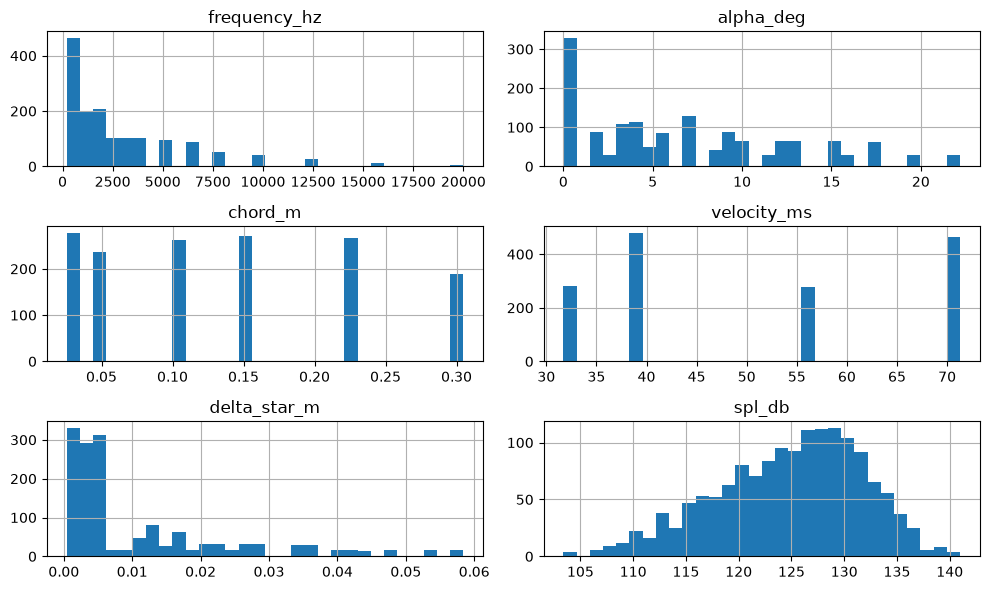

In [8]:
df.hist(figsize=(10,6), bins = 30)
# 10 wide 6 tall, bins=30 means split each column range into 30 equal width bars
plt.tight_layout()
plt.savefig("../results/histograms.png", dpi = 150)
# dpi = figsize * dpi, higher dpi higher pixel, more clear
plt.show()

In [9]:
# Exact number of rows for each velocity and chord setting
print(df["velocity_ms"].value_counts().sort_index())
print()
print(df["chord_m"].value_counts().sort_index())

velocity_ms
31.7    281
39.6    480
55.5    277
71.3    465
Name: count, dtype: int64

chord_m
0.0254    278
0.0508    237
0.1016    263
0.1524    271
0.2286    266
0.3048    188
Name: count, dtype: int64


## 10. How wind speed changes the noise

**What the graph shows:** each line is one wind tunnel test on the same blade (chord 0.3048 m, angle 0°) at a different wind speed. Moving left to right goes from low to high pitch and the height of each point is how loud the noise is at that pitch.

**What I found**
- **Every curve has the same basic shape:** quieter at low pitch, loudest at a mid-range pitch, then much quieter at high pitch.
- **The loudest pitch moves higher as speed increases:** 800 Hz at 31.7 m/s compared with 1600 Hz at 71.3 m/s. Faster flow sweeps the noise-making eddies past the blade more quickly, which raises the pitch.
- **Faster wind adds more high-pitched noise:** above about 1,500 Hz, the faster speeds are clearly louder.
- **But faster isn't louder everywhere:** below 1,000 Hz the two slowest speeds are actually the loudest and the peak levels are similar for all
  four speeds (128 dB to 129 dB).

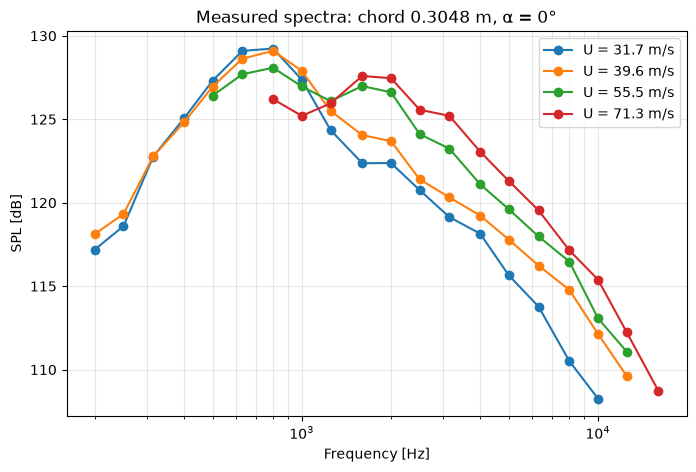

In [ ]:
# Spectra for one blade (largest chord, 0° angle) at each tested speed
subset = df[(df["chord_m"] == 0.3048) & (df["alpha_deg"] == 0)]
fig, ax = plt.subplots(figsize=(8, 5))

# subset: chord length = 0.3048 & alpha_deg = 0
# .groupby("velocity_ms") splits those rows into piles by wind speed. That’s 4 piles: 31.7, 39.6, 55.5 and 71.3 m/s.
# ax.semilogx(x, y) draws a line with the x-axis on a log scale
# x = frequency , y = SPL, "o" = dot, label=f"U = {vel} m/s" means the legend
for vel, group in subset.groupby("velocity_ms"):
    group = group.sort_values("frequency_hz") # puts the rows in order from lowest to highest frequency
    ax.semilogx(group["frequency_hz"], group["spl_db"], marker="o", label=f"U = {vel} m/s")

ax.set_xlabel("Frequency [Hz]") # Pitch, how sharp is it
ax.set_ylabel("SPL [dB]") # Sound pressure level, how loud is it
ax.set_title("Measured spectra: chord 0.3048 m, α = 0°")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.savefig("../results/example_spectra.png", dpi=150)
plt.show()

## Summary

**Data quality**
- The data is clean: 1503 rows, no missing values and no duplicates.
- All ranges match the UCI documentation, except that angle of attack has 27 values (0°–22.2°), so it's continuous, not "Binary" as UCI says.

**How the data is structured**
- It comes from **106 wind-tunnel tests**, each measured at about 14 of the 21 frequency bands on average, so not every test covers every frequency.
- Rows from the same test are very similar, so when I validate my models I'll keep whole tests together (grouped cross-validation).
- **Delta star** has exactly one value per test, so it was calculated from the test conditions rather than measured separately.
- Coverage is uneven: 39.6 m/s and 71.3 m/s have about 1.7× more rows than the other two speeds and the largest chord (0.3048 m) has the fewest rows.

**What the noise looks like**
- Each spectrum rises to a peak at a mid-range pitch and drops off at high pitch.
- Faster wind adds more high-pitched noise and the loudest pitch jumps from about 800 Hz to 1,600 Hz at the highest speed.
- The peak levels barely change with speed, so the data doesn't follow simple U⁵ scaling. I'll treat this as something to investigater rather than assume it.

**What I'll do next because of this**
- Log-transform frequency and delta star, since both are heavily skewed.
**In the histograms, frequency and delta star are bunched up at small values with a long tail. Most frequencies are below 5000 Hz, but a few go up to 20,000.
**Log10 spreads them evenly, matching how pitch is perceived.
- Try the Strouhal number (f·(delta star)/U) as an extra input because the peak shifts with speed.
**In the spectra plot, the loudest pitch moves when the speed changes. 
**Strouhal number St = f·δ*/U: the noise peak occurs at a roughly similar St across tests (Brooks et al., 1989), so give it to the model as a feature.
**Test whether it improves accuracy.

- Expect the model to be weakest at the less common speeds and the largest chord.
**Some settings have much less data. 31.7 and 55.5 m/s have about 280 rows each, versus about 470 for the others, and the 0.3048 m chord has only 188 rows. 
**Fewer examples of a setting means less practice, so predictions there are likely to be worse.